# Euclidean distance, global shifts and DTW — 2026-10-14

A revised analysis and figure notebook using the completed **2026-09-24 focused extraction (pyspi computation r7)**: 50 independent MTS instances per condition, 350 recordings. The notebook date is the analysis date; no new extraction is implied.

In [1]:
from pathlib import Path
import sys, json
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.cases.refresh_case_figures import (
    analyze, plot_pair_rainclouds, plot_rmi_channel_pairs,
    plot_mi_sensitivity, plot_spi_planes, plot_dtw_pair_sweep,
)
DATA = ROOT / 'data/cases/dtw-euclidean-260924/data'
OUT = ROOT / 'results/cases/dtw-euclidean-261014'
# Reanalyse the archived focused SPIs; do not recompute or mix computation versions.
frame = analyze(DATA, 'dtw', OUT)
audit = json.loads((OUT / 'audit.json').read_text())
print(f"{audit['datasets']} datasets; {len(audit['spis'])} focused SPIs; {audit['nonfinite_off_diagonal_values']} nonfinite off-diagonal values")

350 datasets; 3 focused SPIs; 0 nonfinite off-diagonal values


Construction: noisy copies of an AR(1) mother ($a=0.5$) receive fixed integer lags spanning 0–5 and independent local rebound warps. At each path decision, probability $p_{\rm step}$ initiates a size-3 excursion; otherwise the path advances diagonally. This parameter is a path-generation probability, not the fraction of samples warped. Channels are then standardised. Noise standard deviations are uniform on $[0.1/2.718,\,0.1\times2.718]$. Existing recordings have $M=20$, $T=1000$; future cases can be smaller.

The seven conditions are no lag/no warp; lag only; then lag plus $p_{\rm step}\in\{0.1,0.3,0.5,0.7,0.9\}$. The distinction is the allowed alignment: Euclidean compares contemporaneous samples, shifted distance permits one global displacement, and DTW permits local time deformation.

All three distances use squared-error costs followed by a square root and division by $\sqrt T$. Shifted distance minimises over shifts -10 through 10, including boundary costs; unrestricted DTW permits a larger set of paths. Thus $\mathrm{DTW}\leq\mathrm{shifted}\leq\mathrm{Euclidean}$ is structural, not evidence of correct physical alignment. The divisor is record length, not path length. There are no hierarchy violations among the 66,500 unique pairs in these recordings.

Predetermined instance 0 illustrates no lag/no warp, lag only, and heavy warping. Colour shows absolute generating lag difference; dashed lines mark equality. Each boxed panel has matching x/y scales, with limits varying between panels. Lag spreads Euclidean distances according to timing mismatch; a single shift resolves much of this, while local warping creates variation that one shift cannot absorb.

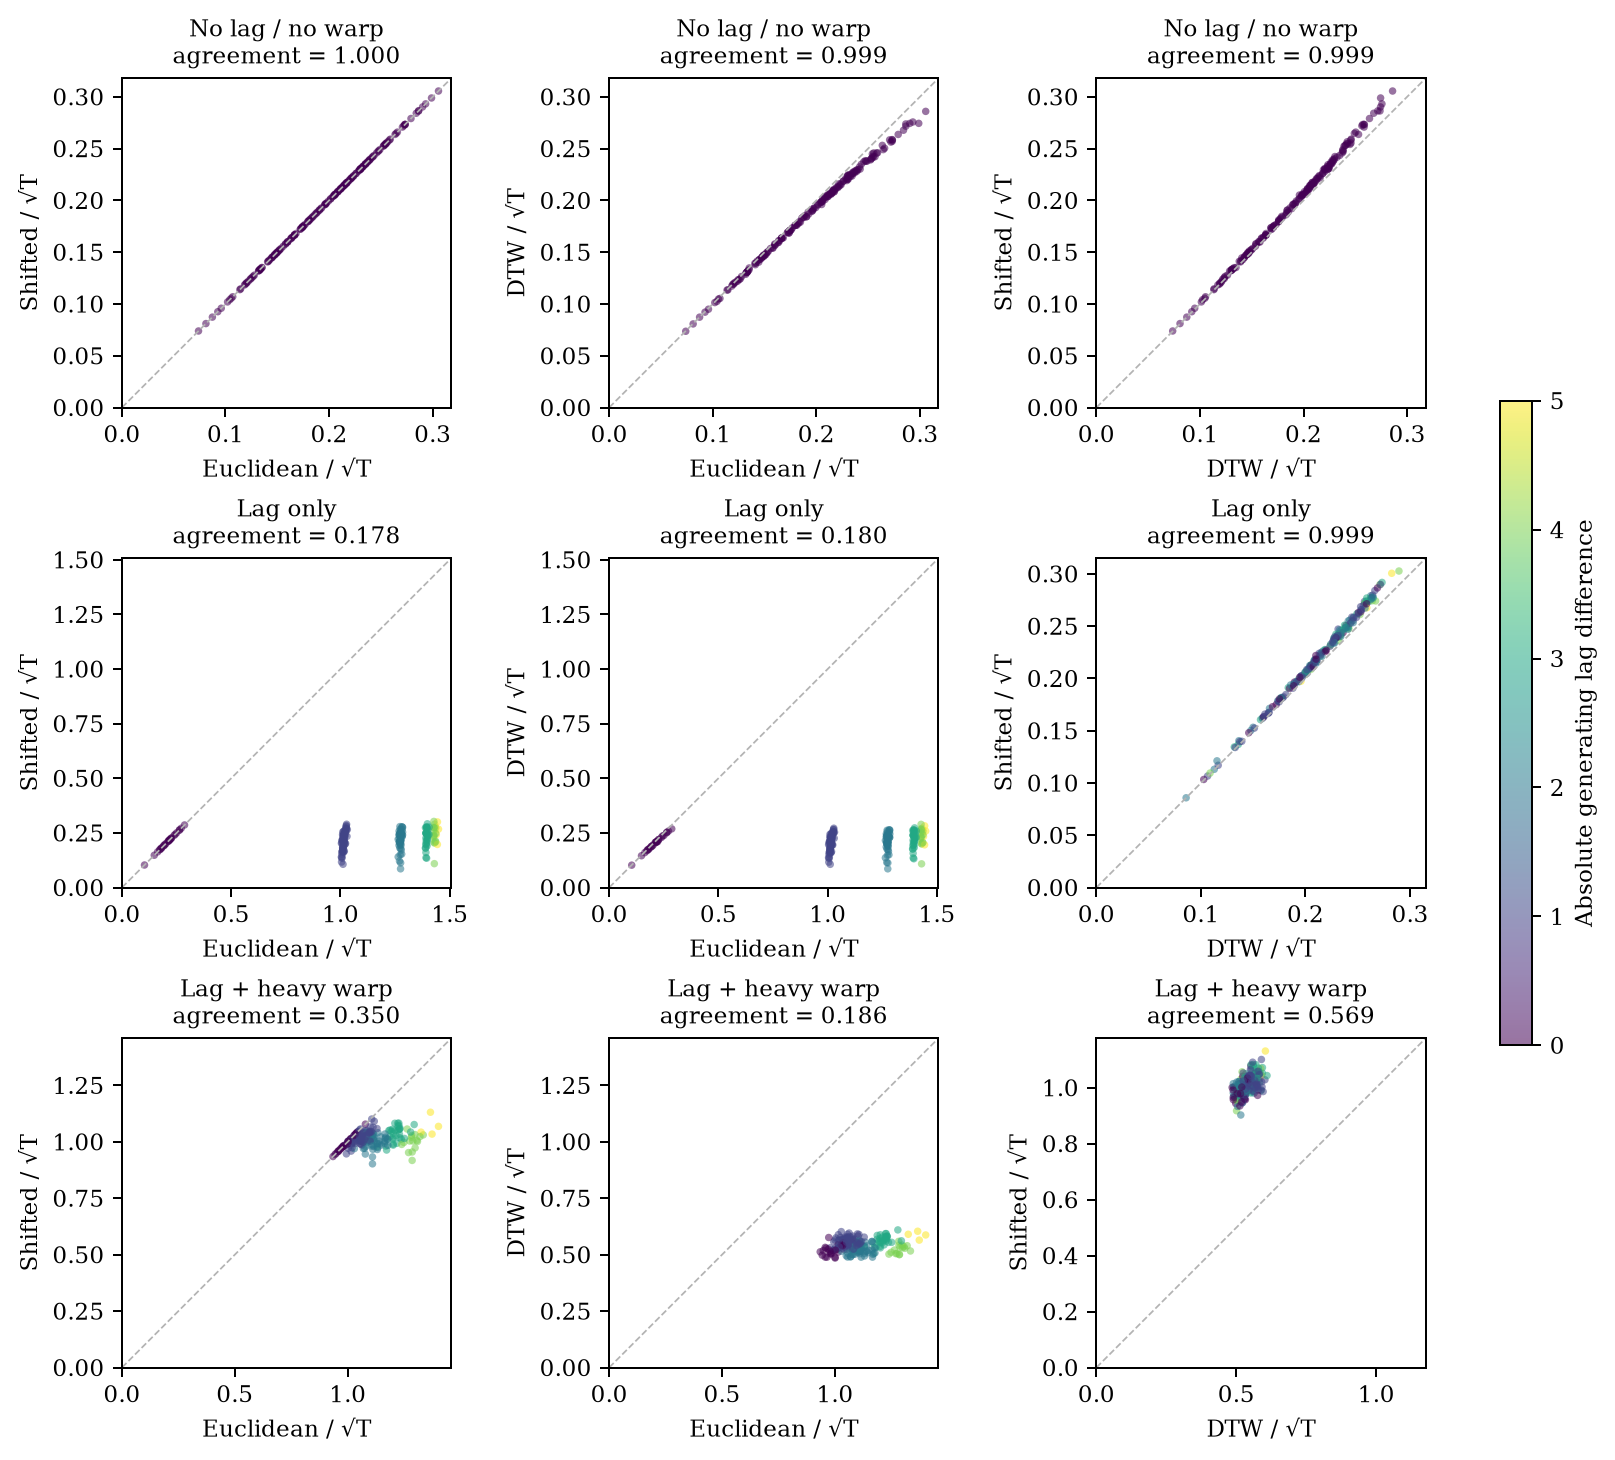

In [2]:
fig = plot_spi_planes(frame, 'dtw', OUT)
plt.show()

For each recording, $z_{ab}=\mathrm{corr}_{i<j}(A^{(a)}_{ij},A^{(b)}_{ij})$. This measures linear agreement between SPI profiles over unique unordered channel pairs. Channel pairs within one recording are dependent; the independent replication unit is the MTS instance. Constant profiles have undefined $z$. The sweep shows mean $z$, with pointwise 95% Student-t intervals over 50 independent recordings. Each SPI pair has its own y-scale, held fixed across conditions. The no-lag control is separated from the connected lagged sweep because it changes a second parameter.

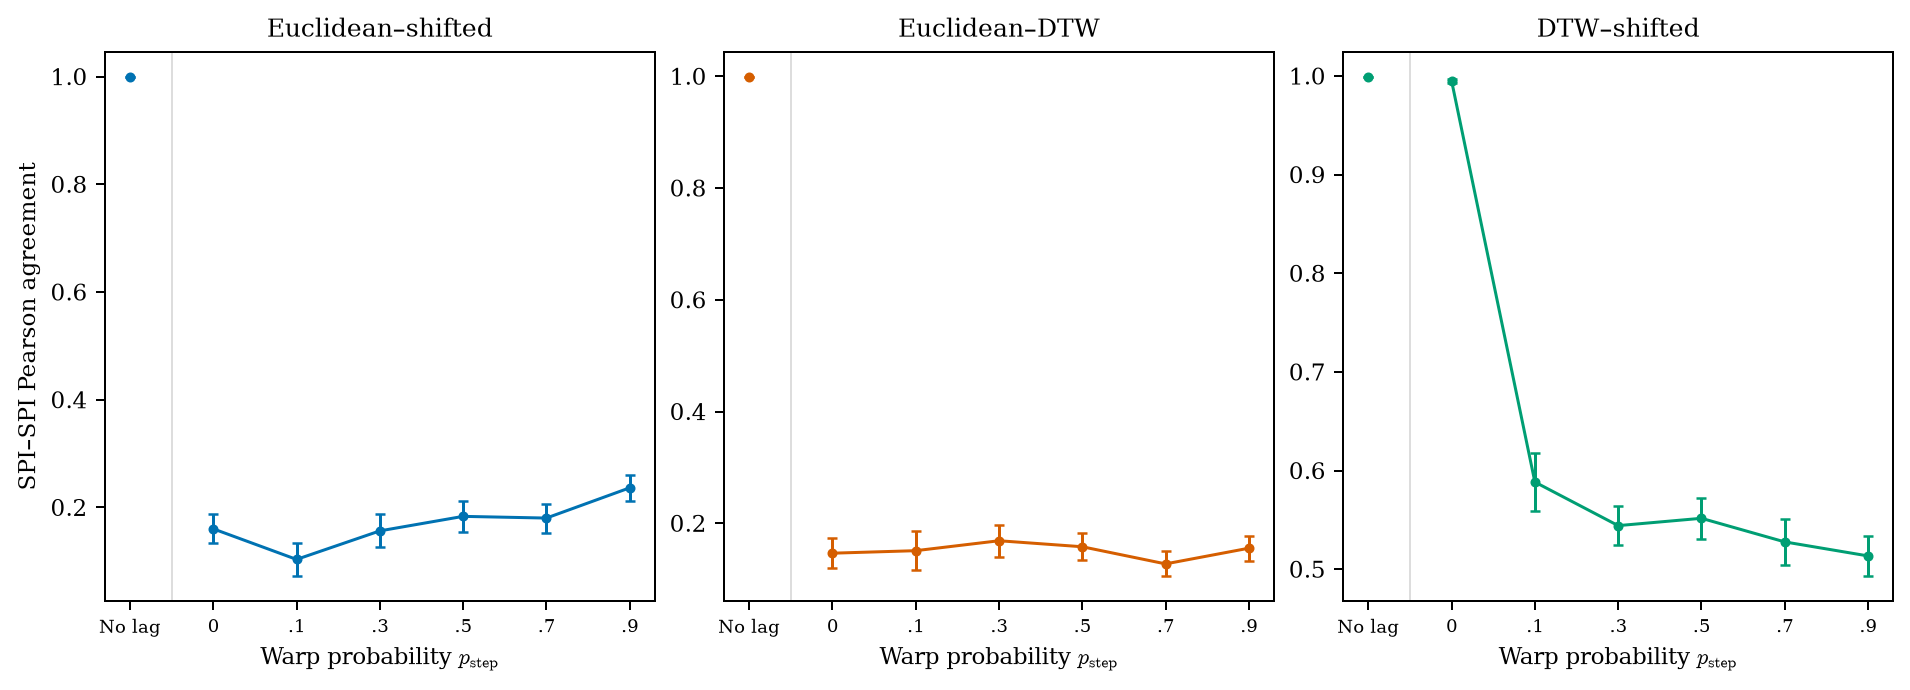

In [3]:
fig = plot_dtw_pair_sweep(frame, OUT)
plt.show()

Lag alone separates Euclidean from both alignment-aware distances, while mean DTW–shifted agreement stays about 0.995. With local warping, the latter falls to roughly 0.51–0.59; the decline is not strictly monotonic with path-step probability. This supports a distinction between global and local alignment tolerance, not a calibrated measure of warp amount.

The generating lag need not equal the best fitted shift for each noisy, warped pair. Nor does a lower DTW cost imply recovery of the generating path. The next useful refinement would plot actual generating time maps alongside alignments and quantify realised deformation before claiming a dose-response. The present SPI–SPI mechanism does not require that claim.

Configurations: `research/cases/ed_xed_dtw/configs/260924_lagged-warping.yaml` and `260924_lagged-warping-extra.yaml`; SPI definitions: `research/cases/ed_xed_dtw/spis/dtw_euclidean_norm.yaml`. Figures and audits are saved under `results/cases/dtw-euclidean-261014/`.